# 02 — Image Preprocessing

## Objective

Prepare the brain image dataset for CNN training.

The dataset contains four classes:

- Glioma
- Meningioma
- No tumor
- Pituitary

From the exploration notebook, we know that the dataset
contains 7,023 original images.

Our previous audit identified 297 extra exact duplicate
files, leaving 6,726 unique file contents.

## Preprocessing workflow

1. Collect image paths and class labels.
2. Detect and exclude exact duplicate files.
3. Split the images into training, validation, and testing sets.
4. Convert images to a consistent grayscale representation.
5. Resize images while preserving their aspect ratio.
6. Normalize pixel values.
7. Prepare labels and verify the final data.

The original images will not be modified.

## Important consideration

Preprocessing must avoid data leakage.

Exact duplicate images should not appear in different
dataset splits. We must also investigate possible
patient-level duplication and visual artifacts that
could make model evaluation misleading.

In [4]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib

import numpy as np
import cv2
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw")

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

print("Dataset directory:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.is_dir())


Dataset directory: /home/houssam/Desktop/Briefs/Brief 4/data/raw
Dataset exists: True


In [5]:
image_records = []

for label in CLASS_NAMES:

    class_dir = DATA_DIR / label

    for path in sorted(class_dir.rglob("*")):

        if path.is_file() and path.suffix.lower() in EXTENSIONS:

            image_records.append((path, label))

print("Total images:", len(image_records))

class_counts = Counter(
    label for path, label in image_records
)

for label in CLASS_NAMES:
    print(f"{label}: {class_counts[label]}")


Total images: 7023
glioma: 1621
meningioma: 1645
notumor: 2000
pituitary: 1757


## 1. Exact Duplicate Detection

Duplicate images can introduce bias into model training
and cause data leakage if identical files appear in
different dataset splits.

We use SHA-256 to group files with identical contents.

For each group, we keep one representative image.

The original files remain unchanged.

Note: SHA-256 identifies exact file duplicates. Images
that look identical but have different encodings or
compression may not have identical hashes.


In [6]:
# Group files by their SHA-256 hash
hash_groups = defaultdict(list)

for path, label in image_records:

    file_hash = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    hash_groups[file_hash].append((path, label))


# Identify duplicate groups
duplicate_groups = [
    group
    for group in hash_groups.values()
    if len(group) > 1
]


# Check for contradictory labels
cross_class_duplicates = [
    group
    for group in duplicate_groups
    if len({label for path, label in group}) > 1
]

if cross_class_duplicates:
    raise ValueError(
        "Identical files have different class labels. "
        "These conflicts must be reviewed."
    )


# Keep one representative per unique file
unique_records = [
    group[0]
    for group in hash_groups.values()
]

unique_records.sort(
    key=lambda record: (record[1], str(record[0]))
)


print("Original files:", len(image_records))
print("Unique files:", len(unique_records))
print("Duplicate groups:", len(duplicate_groups))
print("Extra copies excluded:",
      len(image_records) - len(unique_records))
print("Cross-class duplicate groups:",
      len(cross_class_duplicates))


print("\nUnique images per class:")

unique_counts = Counter(
    label for path, label in unique_records
)

for label in CLASS_NAMES:
    print(f"{label}: {unique_counts[label]}")


Original files: 7023
Unique files: 6726
Duplicate groups: 194
Extra copies excluded: 297
Cross-class duplicate groups: 0

Unique images per class:
glioma: 1620
meningioma: 1635
notumor: 1731
pituitary: 1740



## 2. Stratified Dataset Splitting

After removing exact duplicate files, we have 6,726
unique images.

We will divide them into:

- Training set (70%): used to learn model parameters.
- Validation set (15%): used for model selection,
  hyperparameter tuning, and monitoring overfitting.
- Test set (15%): reserved for final model evaluation.

We use stratified sampling to preserve the proportions
of our four classes across all three sets.

The random state is fixed at 42 to make the split
reproducible.

The split is performed before image augmentation or
other training-specific transformations.

Note: This is an image-level split. Patient-level
independence cannot be guaranteed without patient
identifiers or grouping information.


In [7]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib

# Dataset configuration
DATA_DIR = Path("../data/raw")

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Step 1: Collect image paths and labels
image_records = []

for label in CLASS_NAMES:
    class_dir = DATA_DIR / label

    for path in sorted(class_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            image_records.append((path, label))

# Step 2: Group identical files by SHA-256
hash_groups = defaultdict(list)

for path, label in image_records:
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups[file_hash].append((path, label))

# Step 3: Check for identical files with conflicting labels
cross_class_duplicates = [
    group
    for group in hash_groups.values()
    if len({label for path, label in group}) > 1
]

if cross_class_duplicates:
    raise ValueError("Cross-class duplicate files detected.")

# Step 4: Keep one copy per unique file
unique_records = [
    group[0]
    for group in hash_groups.values()
]

unique_records.sort(
    key=lambda record: (record[1], str(record[0]))
)

# Verify
print("Original images:", len(image_records))
print("Unique images:", len(unique_records))
print("Duplicates excluded:", len(image_records) - len(unique_records))
print("Cross-class duplicate groups:", len(cross_class_duplicates))

print("\nClass distribution:")
counts = Counter(label for path, label in unique_records)

for label in CLASS_NAMES:
    print(f"{label}: {counts[label]}")


Original images: 7023
Unique images: 6726
Duplicates excluded: 297
Cross-class duplicate groups: 0

Class distribution:
glioma: 1620
meningioma: 1635
notumor: 1731
pituitary: 1740


In [8]:
from sklearn.model_selection import train_test_split

In [9]:
from sklearn.model_selection import train_test_split

# Extract class labels for stratification
labels = [label for path, label in unique_records]

# First split: 70% training, 30% temporary
train_records, temp_records = train_test_split(
    unique_records,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Extract temporary labels
temp_labels = [
    label for path, label in temp_records
]

# Second split: 15% validation, 15% testing
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Training:", len(train_records))
print("Validation:", len(val_records))
print("Testing:", len(test_records))
print(
    "Total:",
    len(train_records) + len(val_records) + len(test_records)
)


Training: 4708
Validation: 1009
Testing: 1009
Total: 6726


In [10]:
splits = {
    "Training": train_records,
    "Validation": val_records,
    "Testing": test_records
}

for split_name, records in splits.items():

    counts = Counter(label for path, label in records)

    print(f"\n{split_name} ({len(records)} images)")

    for label in CLASS_NAMES:

        percentage = counts[label] / len(records) * 100

        print(
            f"{label}: {counts[label]} "
            f"({percentage:.2f}%)"
        )


# Check for overlapping file paths
train_paths = {path for path, label in train_records}
val_paths = {path for path, label in val_records}
test_paths = {path for path, label in test_records}

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("\nNo overlapping file paths between splits.")



Training (4708 images)
glioma: 1134 (24.09%)
meningioma: 1144 (24.30%)
notumor: 1212 (25.74%)
pituitary: 1218 (25.87%)

Validation (1009 images)
glioma: 243 (24.08%)
meningioma: 245 (24.28%)
notumor: 260 (25.77%)
pituitary: 261 (25.87%)

Testing (1009 images)
glioma: 243 (24.08%)
meningioma: 246 (24.38%)
notumor: 259 (25.67%)
pituitary: 261 (25.87%)

No overlapping file paths between splits.


In [11]:
import csv

PROJECT_DIR = Path("..").resolve()
SPLIT_DIR = PROJECT_DIR / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = SPLIT_DIR / "split_manifest.csv"

with open(manifest_path, "w", newline="") as file:

    writer = csv.writer(file)
    writer.writerow(["path", "label", "split"])

    for split_name, records in [
        ("train", train_records),
        ("validation", val_records),
        ("test", test_records)
    ]:

        for path, label in records:

            relative_path = (
                path.resolve()
                .relative_to(PROJECT_DIR)
            )

            writer.writerow([
                relative_path.as_posix(),
                label,
                split_name
            ])

print("Saved:", manifest_path)


Saved: /home/houssam/Desktop/Briefs/Brief 4/data/splits/split_manifest.csv


## Class Imbalance Analysis

After exact duplicate removal, the expected dataset
contains 6,726 unique images across four classes.

The class distribution is approximately:

- Glioma: 24.09%
- Meningioma: 24.31%
- No tumor: 25.74%
- Pituitary: 25.87%

The dataset has only mild class imbalance.

### Decision

We will not apply oversampling, undersampling,
or class weighting at this stage.

We will use stratified splitting to preserve the
class proportions in the training, validation,
and test sets.

After training, we will examine per-class
precision, recall, F1-score, and the confusion
matrix to determine whether imbalance handling
is necessary.

Any future balancing technique will be applied
only to the training set.



## 3. Image Standardization

Our raw images have different resolutions and channel
arrangements.

A CNN requires a consistent input shape.

We will standardize all images to:

- Width: 224 pixels
- Height: 224 pixels
- Channels: 1 (grayscale)

### Preprocessing operations

1. Load the original image.
2. Convert it to grayscale.
3. Resize it while preserving its aspect ratio.
4. Apply black padding to obtain a 224 × 224 image.

We use INTER_AREA when reducing image dimensions
and INTER_LINEAR when enlarging them.

This approach avoids stretching anatomical structures.

The original image files are not modified.

We will normalize pixel intensities in the next section.


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_SIZE = 224


def preprocess_image(path):

    # 1. Load image
    image = cv2.imread(
        str(path),
        cv2.IMREAD_UNCHANGED
    )

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    # 2. Convert to grayscale
    if image.ndim == 2:
        gray = image

    elif image.shape[2] == 3:
        gray = cv2.cvtColor(
            image, cv2.COLOR_BGR2GRAY
        )

    elif image.shape[2] == 4:
        gray = cv2.cvtColor(
            image, cv2.COLOR_BGRA2GRAY
        )

    else:
        raise ValueError(
            f"Unsupported shape: {image.shape}"
        )

    if gray.dtype != np.uint8:
        raise ValueError(
            f"Expected uint8 image, got {gray.dtype}: {path}"
        )

    # 3. Preserve aspect ratio
    height, width = gray.shape

    scale = min(
        IMAGE_SIZE / width,
        IMAGE_SIZE / height
    )

    new_width = round(width * scale)
    new_height = round(height * scale)

    # 4. Resize image
    interpolation = (
        cv2.INTER_AREA
        if scale < 1
        else cv2.INTER_LINEAR
    )

    resized = cv2.resize(
        gray,
        (new_width, new_height),
        interpolation=interpolation
    )

    # 5. Create black canvas
    canvas = np.zeros(
        (IMAGE_SIZE, IMAGE_SIZE),
        dtype=np.uint8
    )

    # 6. Center resized image
    x = (IMAGE_SIZE - new_width) // 2
    y = (IMAGE_SIZE - new_height) // 2

    canvas[
        y:y + new_height,
        x:x + new_width
    ] = resized

    return canvas


glioma: (512, 512, 3) -> (224, 224), dtype=uint8
meningioma: (278, 440, 3) -> (224, 224), dtype=uint8
notumor: (236, 236, 3) -> (224, 224), dtype=uint8
pituitary: (512, 512, 3) -> (224, 224), dtype=uint8


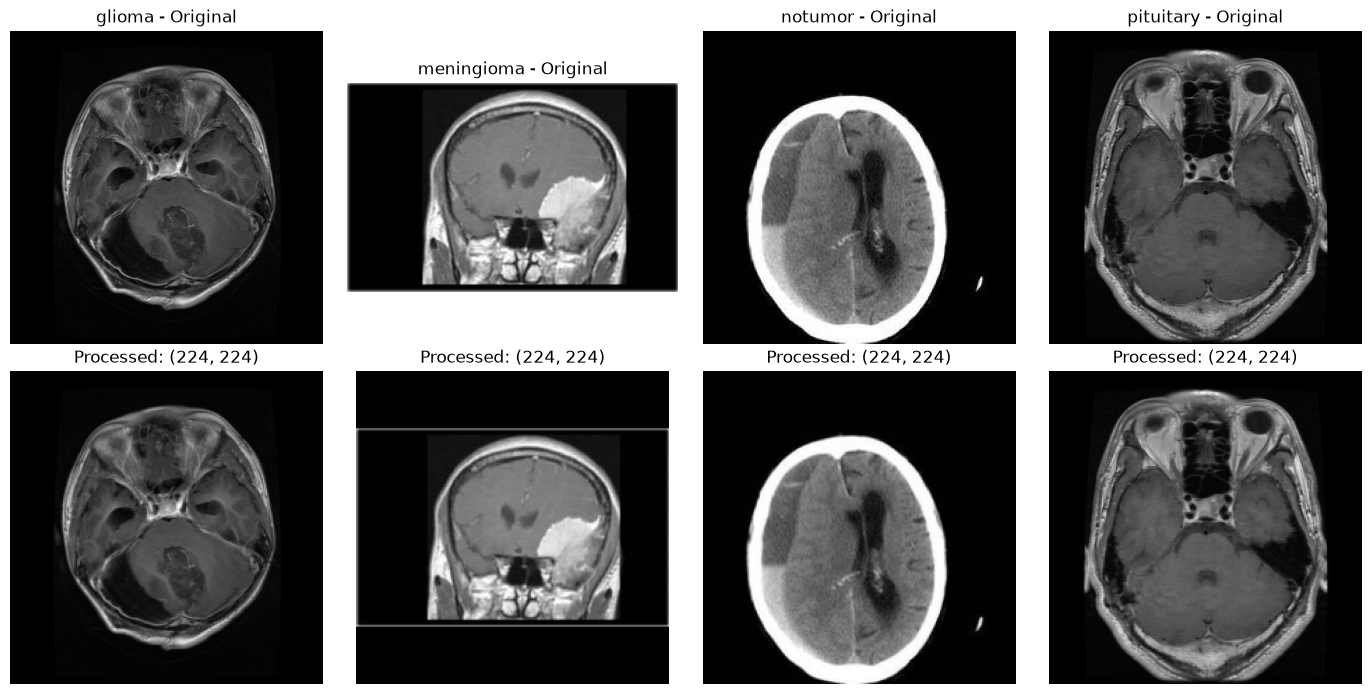

In [13]:
# Choose one image from each class
sample_records = [
    next(
        (path, label)
        for path, label in unique_records
        if label == class_name
    )
    for class_name in CLASS_NAMES
]

fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

for i, (path, label) in enumerate(sample_records):

    original = cv2.imread(
        str(path),
        cv2.IMREAD_UNCHANGED
    )

    processed = preprocess_image(path)

    # Display original with correct colors
    if original.ndim == 2:
        axes[0, i].imshow(original, cmap="gray")
    elif original.shape[2] == 4:
        axes[0, i].imshow(
            cv2.cvtColor(original, cv2.COLOR_BGRA2RGB)
        )
    else:
        axes[0, i].imshow(
            cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
        )

    axes[0, i].set_title(f"{label} - Original")
    axes[0, i].axis("off")

    # Display processed image
    axes[1, i].imshow(processed, cmap="gray")
    axes[1, i].set_title(
        f"Processed: {processed.shape}"
    )
    axes[1, i].axis("off")

    print(
        f"{label}: "
        f"{original.shape} -> {processed.shape}, "
        f"dtype={processed.dtype}"
    )

plt.tight_layout()
plt.show()



### Visual Quality Check

After standardization, all four inspected images have
the expected shape of 224 × 224 and use uint8 values.

The aspect ratio is preserved through resizing and padding.

However, visual inspection revealed a possible imaging
modality inconsistency: a no-tumor sample appears CT-like,
while the inspected tumor samples appear MRI-like.

This could introduce a spurious correlation between the
image modality and the target class.

Before training, we will inspect additional samples from
every class to investigate potential modality differences,
annotations, and other source-related artifacts.


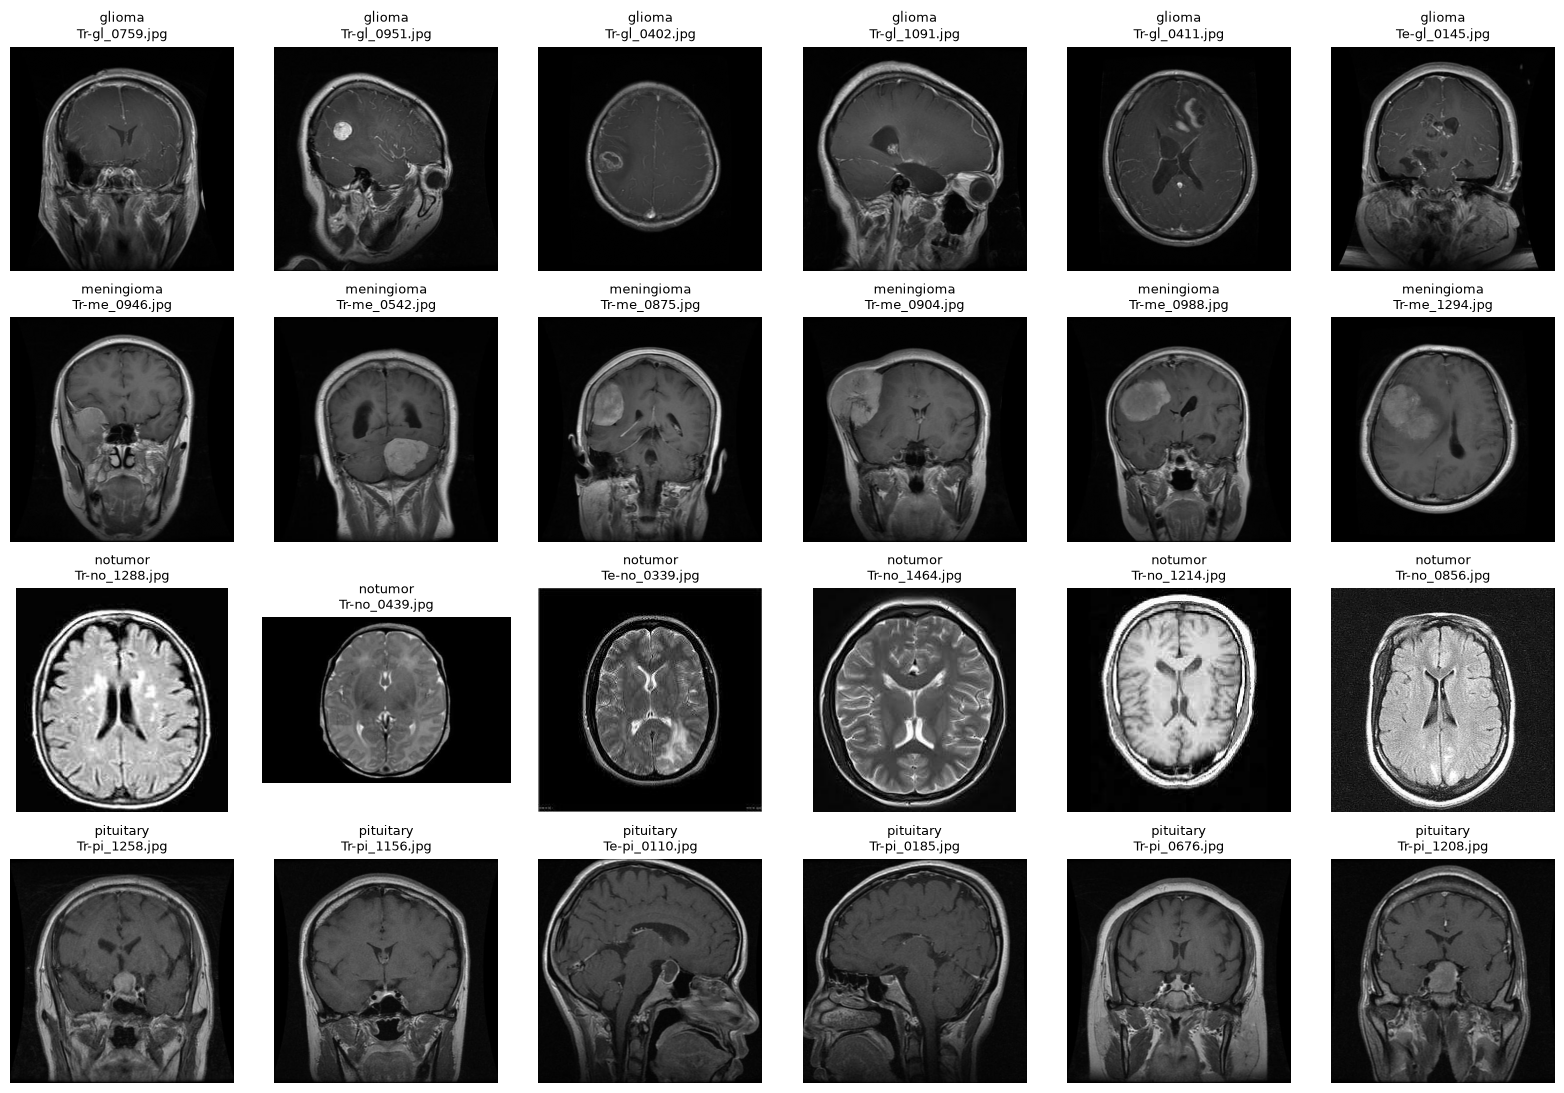

In [14]:
rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    4, 6,
    figsize=(16, 11)
)

for row, label in enumerate(CLASS_NAMES):

    class_paths = [
        path
        for path, class_label in unique_records
        if class_label == label
    ]

    indices = rng.choice(
        len(class_paths),
        size=6,
        replace=False
    )

    for col, idx in enumerate(indices):

        path = class_paths[idx]

        image = cv2.imread(
            str(path),
            cv2.IMREAD_UNCHANGED
        )

        if image.ndim == 2:
            axes[row, col].imshow(image, cmap="gray")

        elif image.shape[2] == 4:
            axes[row, col].imshow(
                cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA)
            )

        else:
            axes[row, col].imshow(
                cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            )

        axes[row, col].set_title(
            f"{label}\n{path.name}",
            fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()



### Visual Inspection Findings

We visually inspected six randomly selected images from each
of the four classes.

Observations:

- The inspected tumor-class images appear predominantly MRI-based.
- The inspected no-tumor images also appear MRI-based, although
  an earlier example appeared CT-like.
- MRI contrast characteristics and anatomical viewing planes
  appear to differ across classes.
- Some images contain borders or other presentation artifacts.

### Potential Risk

The CNN may learn acquisition characteristics, viewing planes,
or presentation artifacts rather than tumor-related features.

### Decision

We will proceed with an educational baseline CNN while
documenting these limitations.

Image appearance alone does not establish the imaging modality
or MRI sequence. Further source verification would be required
for a clinically reliable evaluation.



## 4. Pixel Normalization

After standardization, the images have dimensions of
224 × 224 and use the uint8 data type.

Pixel values range from 0 to 255.

We normalize pixel intensities by dividing them by 255.

The resulting pixel values range from 0 to 1.

We use float32 because neural networks operate on
floating-point numbers.

We also add a channel dimension so the final image
shape becomes (224, 224, 1).

Normalization changes pixel intensity values, not
the image dimensions or the target label.


In [15]:
def normalize_image(image):

    # Convert pixels to float32 and normalize
    normalized = image.astype(np.float32) / 255.0

    # Add the channel dimension
    normalized = normalized[:, :, np.newaxis]

    return normalized


In [16]:
# Select one example from our deduplicated records
path, label = unique_records[0]

# Standardize
processed = preprocess_image(path)

# Normalize
normalized = normalize_image(processed)

print("Class:", label)

print("\nBefore normalization:")
print("Shape:", processed.shape)
print("Data type:", processed.dtype)
print("Minimum:", processed.min())
print("Maximum:", processed.max())

print("\nAfter normalization:")
print("Shape:", normalized.shape)
print("Data type:", normalized.dtype)
print("Minimum:", normalized.min())
print("Maximum:", normalized.max())


Class: glioma

Before normalization:
Shape: (224, 224)
Data type: uint8
Minimum: 0
Maximum: 244

After normalization:
Shape: (224, 224, 1)
Data type: float32
Minimum: 0.0
Maximum: 0.95686275



## 5. Label Encoding

Our dataset contains four categorical labels.

We map each label to an integer:

- glioma: 0
- meningioma: 1
- notumor: 2
- pituitary: 3

The integers represent class identifiers, not an
ordinal relationship between disease categories.

We will use sparse categorical cross-entropy during
model training because our labels are integers.


In [17]:
class_to_id = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

id_to_class = {
    index: class_name
    for class_name, index in class_to_id.items()
}

print("Class to ID:", class_to_id)
print("ID to class:", id_to_class)

# Example
label = "meningioma"
encoded_label = class_to_id[label]

print("\nOriginal label:", label)
print("Encoded label:", encoded_label)
print("Decoded label:", id_to_class[encoded_label])


Class to ID: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
ID to class: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}

Original label: meningioma
Encoded label: 1
Decoded label: meningioma



## 6. Data Pipeline

We use TensorFlow's tf.data API to prepare images for
model training and evaluation.

The pipeline performs the following operations:

1. Read an image from its path.
2. Apply grayscale conversion, resizing, and padding.
3. Normalize pixel intensities to the range [0, 1].
4. Add the channel dimension.
5. Encode the class label as an integer.
6. Group the examples into batches.

### Why use batches?

Loading all images into memory simultaneously can consume
significant RAM.

Batch processing allows us to load and process a smaller
number of images at a time.

We use a batch size of 32.

### Shuffling

The training dataset is shuffled to vary the order of
examples across epochs.

Validation and test datasets are not shuffled to preserve
a stable evaluation order.

### Data leakage prevention

The pipeline uses the already-established training,
validation, and test assignments.

We do not mix images between these sets.


In [ ]:
import tensorflow as tf

def image_generator(records):

    for path, label in records:

        # Standardize image dimensions and channels
        image = preprocess_image(path)

        # Normalize pixel values and add channel dimension
        image = normalize_image(image)

        # Convert the label to an integer
        encoded_label = class_to_id[label]

        yield image, np.int32(encoded_label)
